✅ CRNN Model Loaded

🧾 Detected 39 lines

Line 1:  fKj@A_@E@lZ@g_@_j@@K@@ffl1@jVR_S l Ulj jES
Line 2:  fSSf  l2Z@ej7zg j
Line 3:  f. Gl lUlDj_0lR Rllf lH_lBlHllfJf SGlfl@J
Line 4:   lHlfRdI Sq74IHlf
Line 5:  ASS1stent POfeSSO. DcDa7LmcTt Of FineTCGj UniVcTSel BuS1nSS SCl1OOl. KdTjaE. Ra1ged.
Line 6:  Em1ejl. krutikea.SaWa0Tt@ubS.OFB.im
Line 7:   lHlqSlH7dt1dH1 S0IHf
Line 8:  PGDM tT1 FiT1a01CG. UmivcFSal BuS1TGSS Sch00 EaJjet RaiBad MehearaShtr el.
Line 9:  Emai. 1eFShMaFGheD.SOi@tbS.O7B.iT
Line 10:   lPaTtiIdj Mal1aTdHl
Line 11:  PGDM tT1 FiT1a01CG. UmivcFSal BuS1TGSS Sch00 EaJjet RaiBad MehearaShtr el.
Line 12:  E1ail. PaIthajS1nh.eheTatl@tbS.OTB.101
Line 13:  SHHTH5li SaTMaI
Line 14:  PGDM tT  FiT1a01CG. UmiveSal BuS1TGSS SCh0O. RejeE RaiBad Me1eaTaShtF e.
Line 15:  Emaf. Setabh.aBa7WaJ@ubS.O7B.iT
Line 16:  flfSflRE
Line 17:  Tlhc benkhg indtstfy is defgolng g7Oumd-blcaki0g fcfOlmsj witi a focts On th client as thc
Line 18:  pJlndly drivc. tustors that erc tccl dwarc alad ofte intcl

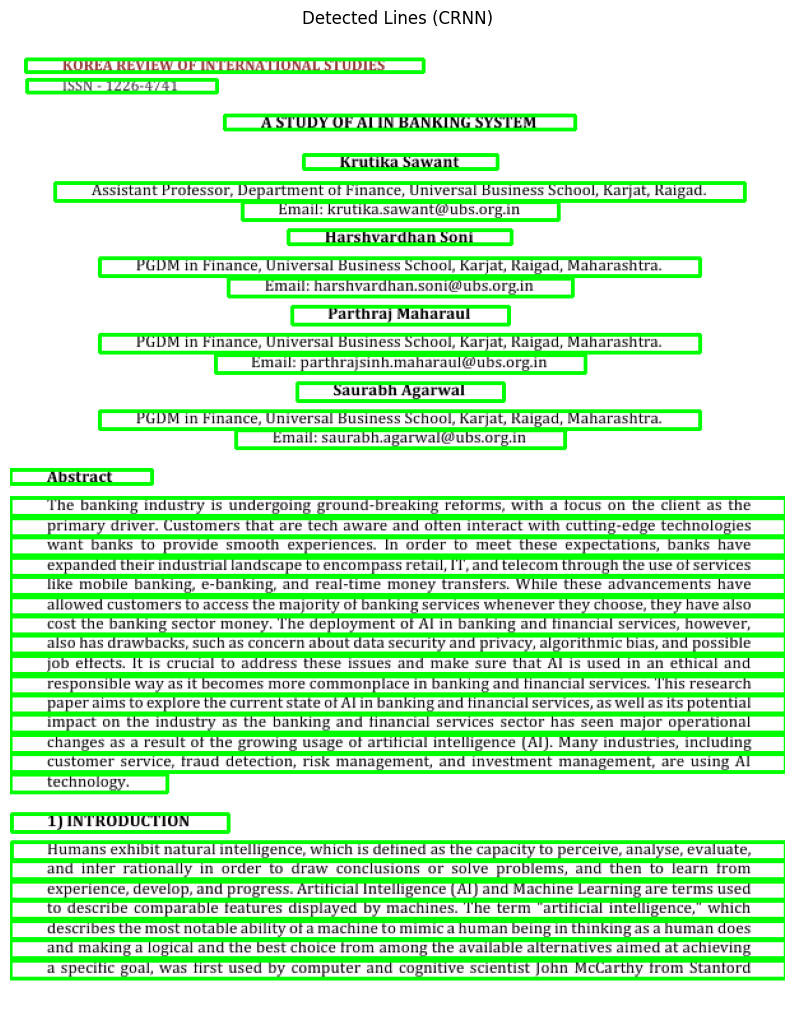


📄 FINAL OUTPUT:

 fKj@A_@E@lZ@g_@_j@@K@@ffl1@jVR_S l Ulj jES
 fSSf  l2Z@ej7zg j
 f. Gl lUlDj_0lR Rllf lH_lBlHllfJf SGlfl@J
  lHlfRdI Sq74IHlf
 ASS1stent POfeSSO. DcDa7LmcTt Of FineTCGj UniVcTSel BuS1nSS SCl1OOl. KdTjaE. Ra1ged.
 Em1ejl. krutikea.SaWa0Tt@ubS.OFB.im
  lHlqSlH7dt1dH1 S0IHf
 PGDM tT1 FiT1a01CG. UmivcFSal BuS1TGSS Sch00 EaJjet RaiBad MehearaShtr el.
 Emai. 1eFShMaFGheD.SOi@tbS.O7B.iT
  lPaTtiIdj Mal1aTdHl
 PGDM tT1 FiT1a01CG. UmivcFSal BuS1TGSS Sch00 EaJjet RaiBad MehearaShtr el.
 E1ail. PaIthajS1nh.eheTatl@tbS.OTB.101
 SHHTH5li SaTMaI
 PGDM tT  FiT1a01CG. UmiveSal BuS1TGSS SCh0O. RejeE RaiBad Me1eaTaShtF e.
 Emaf. Setabh.aBa7WaJ@ubS.O7B.iT
 flfSflRE
 Tlhc benkhg indtstfy is defgolng g7Oumd-blcaki0g fcfOlmsj witi a focts On th client as thc
 pJlndly drivc. tustors that erc tccl dwarc alad ofte intclact iti cutti1g-cdgc tcCOlOgiGS
 WaTt banKS tO_PJOVide SDOOt1 XDOF1c0CGS. In OTdc t0 ncet theSc XDCketiOS. ba01KS aVc
 cXDadcG tlhc1f iadtstrieal landsCaDc tO emCOmDsS 7etailjl.

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from PIL import Image
import cv2
import os
import matplotlib.pyplot as plt

# =========================
# CONFIG
# =========================
MODEL_PATH = "crnn_model_final.pth"
IMAGE_PATH = "anip.png"

IMG_HEIGHT = 32
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# =========================
# CHARSET (EXACT SAME AS TRAINING)
# =========================
CHARS = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789@._- "
char_to_idx = {c: i+1 for i, c in enumerate(CHARS)}
idx_to_char = {i+1: c for i, c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1  # +1 for blank

# =========================
# CRNN MODEL (EXACT SAME)
# =========================
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1,64,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(128,256,3,1,1), nn.ReLU(),
            nn.Conv2d(256,256,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(256,512,3,1,1), nn.ReLU(), nn.BatchNorm2d(512),
            nn.Conv2d(512,512,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(512,512,2,1,0), nn.ReLU()
        )

        self.rnn = nn.LSTM(
            input_size=512,
            hidden_size=256,
            num_layers=2,
            bidirectional=True,
            batch_first=True
        )

        self.fc = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.cnn(x)
        b, c, h, w = x.size()

        assert h == 1

        x = x.squeeze(2).permute(0,2,1)  # (B, W, C)
        x, _ = self.rnn(x)
        x = self.fc(x)

        return x.log_softmax(2)

# =========================
# LOAD MODEL
# =========================
model = CRNN(NUM_CLASSES).to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

print("✅ CRNN Model Loaded")

# =========================
# TRANSFORM (NO FIXED WIDTH!)
# =========================
transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# =========================
# CTC DECODE
# =========================
def ctc_decode(preds):
    preds = preds.argmax(2).cpu().numpy()

    results = []
    for pred in preds:
        prev = -1
        text = ""

        for p in pred:
            if p != prev and p != 0:
                text += idx_to_char.get(p, "")
            prev = p

        results.append(text)

    return results

# =========================
# PREDICT LINE
# =========================
def predict_line(pil_img):
    w, h = pil_img.size
    new_w = max(int(IMG_HEIGHT * w / h), 1)

    pil_img = pil_img.resize((new_w, IMG_HEIGHT), Image.Resampling.LANCZOS)
    img = transform(pil_img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        preds = model(img)

    text = ctc_decode(preds)[0]
    return text

# =========================
# 🔥 LINE DETECTION (BEST)
# =========================
def segment_lines(image_path):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    thresh = cv2.adaptiveThreshold(
        gray, 255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY_INV,
        15, 5
    )

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (60, 3))
    dilated = cv2.dilate(thresh, kernel, iterations=1)

    contours, _ = cv2.findContours(dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    lines = []
    boxes = []

    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)

        if h > 8 and w > 30:
            lines.append((y, gray[y:y+h, x:x+w]))
            boxes.append((x, y, w, h))

    lines = sorted(lines, key=lambda x: x[0])
    boxes = sorted(boxes, key=lambda x: x[1])

    return img, [l for _, l in lines], boxes

# =========================
# RUN OCR
# =========================
img, lines, boxes = segment_lines(IMAGE_PATH)

print(f"\n🧾 Detected {len(lines)} lines\n")

os.makedirs("debug_lines", exist_ok=True)

vis_img = img.copy()
final_text = []

for i, (line, (x,y,w,h)) in enumerate(zip(lines, boxes)):
    cv2.rectangle(vis_img, (x,y), (x+w, y+h), (0,255,0), 2)

    cv2.imwrite(f"debug_lines/line_{i}.png", line)

    pil_img = Image.fromarray(line)
    text = predict_line(pil_img)

    final_text.append(text)
    print(f"Line {i+1}: {text}")

# Save visualization
cv2.imwrite("detected_lines.png", vis_img)

plt.figure(figsize=(10,15))
plt.imshow(cv2.cvtColor(vis_img, cv2.COLOR_BGR2RGB))
plt.title("Detected Lines (CRNN)")
plt.axis("off")
plt.show()

print("\n📄 FINAL OUTPUT:\n")
print("\n".join(final_text))

In [ ]:
# Best possible output untill 29.03.2026

✅ CRNN Model Loaded

🧾 Detected 39 lines

Line 1: _lK0RJ@ l@BV lBMV_0l_JWll5@B.llQlX@tt.  l lUlDlB
Line 2:  _ISSK e_Z5e47Jz1l
Line 3:   9l lUlDl_0M ill l lBJilI@ G5llE0
Line 4:   UflfA WHHlt
Line 5:  SSistamt Dr0fcSS0Jz DeDeJLmcTt 0 J7jmeDCG UmlVeISal BuSlnGSS SCl100l KaIjE. RaIgadz
Line 6:  E01eIf1z KFUKika.SaWat@uDS.0FB.fH
Line 7:  _HaSlhW0LAHl S0ln.5
Line 8:   2GD i0 Fi0alCGz UmfvcrSal BUSfmGSS SCH00z Kejet Raigady MeIheFaSl1te.
Line 9:  Enneilk 1aFShVaI0haD.S00f@ubS.0JgiD
Line 10:  7aItl1rdj alafaUl
Line 11:   2GD i0 Fi0alCGz UmfvcrSal BUSfmGSS SCH00z Kejet Raigady MeIheFaSl1te.
Line 12:  En1aflz PHTt1IejSfmlt.1aheTaU1@uDS.0Fg.1
Line 13:   SBUab ABaIaI
Line 14:   DGD i0 Fi0alCGz UmfvGISal BUSimGSS SCH00z erje Raigady MeJ1eFaSETe.
Line 15:  Enneilk seUTelbh.egaI@ubS.0Jgfm
Line 16:  k0SlrRtGf
Line 17: Tlic baDKfmg fduSEj iS UdeIB01B 8F0UHG-bJeaKig Ief0Im1S Wftt e f0CUS 0n tnG Client aS dhG
Line 18: _Pll6F@ 0rVcz GtSt0mGIS tlet erc tcclt dWaJc amd 0ftel fntcract ft cuttg- Gdge tcCli00

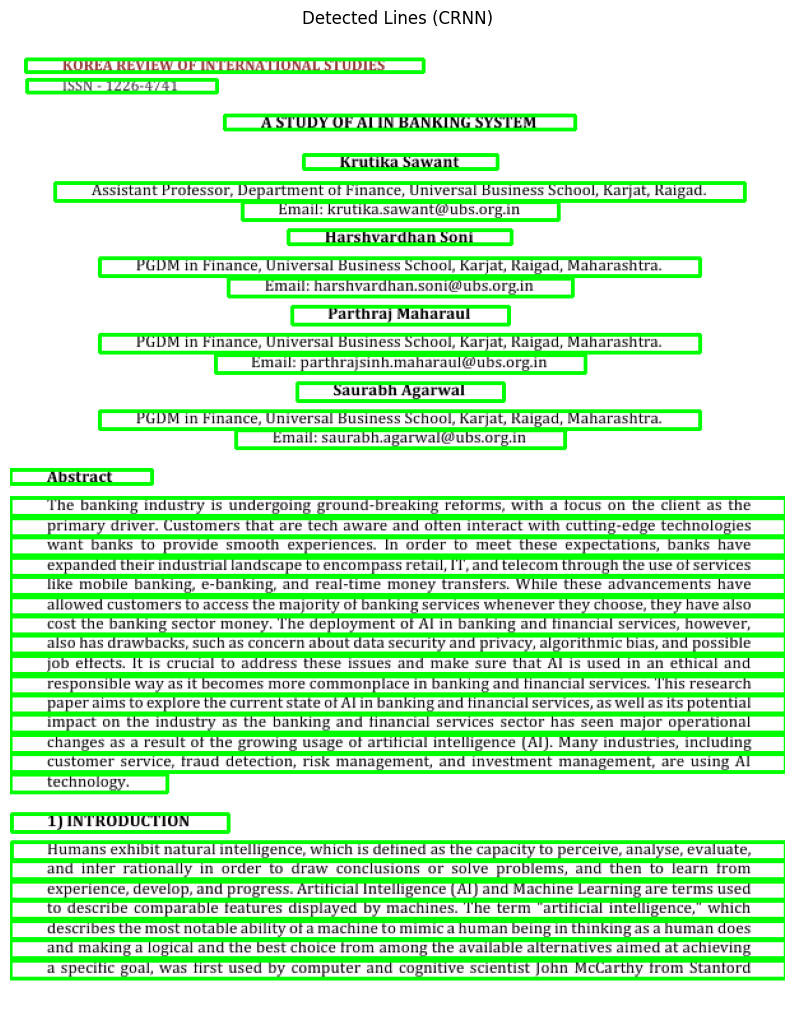


📄 FINAL OUTPUT:

_lK0RJ@ l@BV lBMV_0l_JWll5@B.llQlX@tt.  l lUlDlB
 _ISSK e_Z5e47Jz1l
  9l lUlDl_0M ill l lBJilI@ G5llE0
  UflfA WHHlt
 SSistamt Dr0fcSS0Jz DeDeJLmcTt 0 J7jmeDCG UmlVeISal BuSlnGSS SCl100l KaIjE. RaIgadz
 E01eIf1z KFUKika.SaWat@uDS.0FB.fH
 _HaSlhW0LAHl S0ln.5
  2GD i0 Fi0alCGz UmfvcrSal BUSfmGSS SCH00z Kejet Raigady MeIheFaSl1te.
 Enneilk 1aFShVaI0haD.S00f@ubS.0JgiD
 7aItl1rdj alafaUl
  2GD i0 Fi0alCGz UmfvcrSal BUSfmGSS SCH00z Kejet Raigady MeIheFaSl1te.
 En1aflz PHTt1IejSfmlt.1aheTaU1@uDS.0Fg.1
  SBUab ABaIaI
  DGD i0 Fi0alCGz UmfvGISal BUSimGSS SCH00z erje Raigady MeJ1eFaSETe.
 Enneilk seUTelbh.egaI@ubS.0Jgfm
 k0SlrRtGf
Tlic baDKfmg fduSEj iS UdeIB01B 8F0UHG-bJeaKig Ief0Im1S Wftt e f0CUS 0n tnG Client aS dhG
_Pll6F@ 0rVcz GtSt0mGIS tlet erc tcclt dWaJc amd 0ftel fntcract ft cuttg- Gdge tcCli00l0gfGS
 WaTt aDKS 0_PI0vjQe SH00t1 DeI1G0CGS. Im QJdeI t0 J1eet 6eSe eXDGCEet0Sj baKS 1aVG
GXPdm0Gd GlrGlf fmdus6fel laHGSGaD t0 GDC0ImDaSS Jctafl JTj and teleC0I1 t10Ug 1C USG 

In [10]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt

# =========================
# CONFIG
# =========================
MODEL_PATH = "crnn_model_final.pth"
IMAGE_PATH = "anip.png"

IMG_HEIGHT = 32
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# =========================
# CHARSET (SAME AS TRAINING)
# =========================
CHARS = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789@._- "
idx_to_char = {i+1: c for i, c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1  # +1 for blank

# =========================
# CRNN MODEL
# =========================
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1,64,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(128,256,3,1,1), nn.ReLU(),
            nn.Conv2d(256,256,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(256,512,3,1,1), nn.ReLU(), nn.BatchNorm2d(512),
            nn.Conv2d(512,512,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(512,512,2,1,0), nn.ReLU()
        )

        self.rnn = nn.LSTM(512, 256, num_layers=2, bidirectional=True, batch_first=True)
        self.fc = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.cnn(x)
        b, c, h, w = x.size()
        assert h == 1

        x = x.squeeze(2).permute(0,2,1)  # (B, W, C)
        x, _ = self.rnn(x)
        x = self.fc(x)

        return x.log_softmax(2)

# =========================
# LOAD MODEL
# =========================
model = CRNN(NUM_CLASSES).to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()
print("✅ CRNN Model Loaded")

# =========================
# TRANSFORM
# =========================
transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# =========================
# CTC DECODE
# =========================
def ctc_decode(preds):
    preds = preds.argmax(2).cpu().numpy()
    results = []

    for pred in preds:
        prev = -1
        text = ""
        for p in pred:
            if p != prev and p != 0:
                text += idx_to_char.get(p, "")
            prev = p
        results.append(text)

    return results

# =========================
# PREPROCESS FUNCTION (🔥 KEY)
# =========================
def preprocess_line(line_img):
    img = line_img.copy()

    # Upscale
    img = cv2.resize(img, None, fx=4, fy=4, interpolation=cv2.INTER_CUBIC)

    # Denoise
    img = cv2.fastNlMeansDenoising(img, None, 10, 7, 21)

    # Sharpen
    kernel = np.array([[0,-1,0],
                       [-1,5,-1],
                       [0,-1,0]])
    img = cv2.filter2D(img, -1, kernel)

    # Threshold
    img = cv2.adaptiveThreshold(
        img, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        31, 5
    )

    # Ensure black text on white background
    if np.mean(img) < 127:
        img = 255 - img

    return img

# =========================
# PREDICT LINE
# =========================
def predict_line(img_np):
    pil_img = Image.fromarray(img_np)

    w, h = pil_img.size
    new_w = max(int(IMG_HEIGHT * w / h), 1)

    pil_img = pil_img.resize((new_w, IMG_HEIGHT), Image.Resampling.LANCZOS)
    img = transform(pil_img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        preds = model(img)

    return ctc_decode(preds)[0]

# =========================
# LINE SEGMENTATION
# =========================
def segment_lines(image_path):
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"❌ Image not found: {image_path}")

    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    thresh = cv2.adaptiveThreshold(
        gray, 255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY_INV,
        15, 5
    )

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (60, 3))
    dilated = cv2.dilate(thresh, kernel, iterations=1)

    contours, _ = cv2.findContours(dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    lines, boxes = [], []

    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        if h > 8 and w > 30:
            lines.append((y, gray[y:y+h, x:x+w]))
            boxes.append((x, y, w, h))

    lines = sorted(lines, key=lambda x: x[0])
    boxes = sorted(boxes, key=lambda x: x[1])

    return img, [l for _, l in lines], boxes

# =========================
# RUN OCR
# =========================
img, lines, boxes = segment_lines(IMAGE_PATH)

print(f"\n🧾 Detected {len(lines)} lines\n")

os.makedirs("debug_lines", exist_ok=True)

vis_img = img.copy()
final_text = []

for i, (line, (x,y,w,h)) in enumerate(zip(lines, boxes)):
    cv2.rectangle(vis_img, (x,y), (x+w, y+h), (0,255,0), 2)

    # 🔥 Preprocess
    processed = preprocess_line(line)

    # Save debug
    cv2.imwrite(f"debug_lines/line_{i}.png", processed)

    # Predict
    text = predict_line(processed)

    final_text.append(text)
    print(f"Line {i+1}: {text}")

# =========================
# SAVE + SHOW RESULT
# =========================
cv2.imwrite("detected_lines.png", vis_img)

plt.figure(figsize=(10,15))
plt.imshow(cv2.cvtColor(vis_img, cv2.COLOR_BGR2RGB))
plt.title("Detected Lines (CRNN)")
plt.axis("off")
plt.show()

print("\n📄 FINAL OUTPUT:\n")
print("\n".join(final_text))

✅ Model Loaded

🧾 Detected 40 lines

Line 1: g
Line 2: 
Line 3: 
Line 4: 
Line 5: mgiggggjtggtgggjgjigtgigty
Line 6: 
Line 7: tgggtgsgngglggg@titgrttnittsi  itine
Line 8: 
Line 9: 
Line 10: kisgettspmostggg
Line 11: gligjijlllinttggt@gggtliis
Line 12: sitrtjggizgiiti sgisigt
Line 13: 
Line 14: ggstsstjggtigi titggtittiitring
Line 15: 
Line 16: jjgggtgggis tgigiiitlitjtgss
Line 17: 
Line 18: ail6
Line 19: 
Line 20: at  tistinyitytr feittiesgfgyiititigrggtiriningltirgtige
Line 21: 
Line 22: 
Line 23: 
Line 24: ggg
Line 25: 
Line 26: 
Line 27: 
Line 28: 
Line 29:  iggyi
Line 30: 
Line 31: gi itgnggyigg nigiiditigginggiglingigsistn
Line 32: 
Line 33: 
Line 34: tg
Line 35: 
Line 36: 
Line 37: 
Line 38: 
Line 39: 
Line 40: g


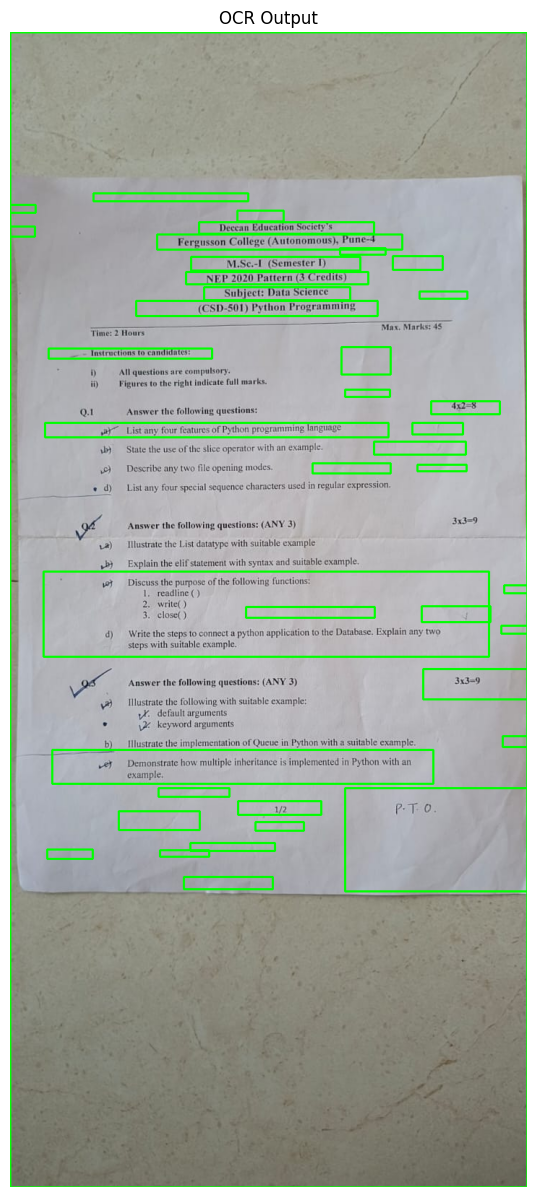

In [13]:
# =========================
# 🔍 OCR TESTING SCRIPT
# =========================

import torch
import torch.nn as nn
from PIL import Image
import torchvision.transforms as transforms
import cv2
import matplotlib.pyplot as plt
import os

# =========================
# CONFIG
# =========================
MODEL_PATH = "crnn_epoch_5.pth"   # change if needed
IMAGE_PATH = "test_2.png"           # 👈 change this for new images

IMG_HEIGHT = 32
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# =========================
# CHARSET (MUST MATCH TRAINING)
# =========================
CHARS = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789@._- "
char_to_idx = {c: i+1 for i,c in enumerate(CHARS)}
idx_to_char = {i+1:c for i,c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1

# =========================
# MODEL
# =========================
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1,64,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(128,256,3,1,1), nn.ReLU(),
            nn.Conv2d(256,256,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(256,512,3,1,1), nn.ReLU(), nn.BatchNorm2d(512),
            nn.Conv2d(512,512,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(512,512,2,1,0), nn.ReLU()
        )

        self.rnn = nn.LSTM(512,256,2,bidirectional=True,batch_first=True)
        self.fc = nn.Linear(512,num_classes)

    def forward(self,x):
        x = self.cnn(x)
        x = x.squeeze(2).permute(0,2,1)
        x,_ = self.rnn(x)
        x = self.fc(x)
        return x.log_softmax(2)

# =========================
# DECODER
# =========================
def decode(preds):
    preds = preds.argmax(2).cpu().numpy()
    results = []

    for pred in preds:
        prev = -1
        text = ""

        for p in pred:
            if p != prev and p != 0:
                text += idx_to_char.get(p, "")
            prev = p

        results.append(text)

    return results

# =========================
# LINE SEGMENTATION
# =========================
def segment_lines(image_path):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    thresh = cv2.adaptiveThreshold(
        gray,255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY_INV,
        15,5
    )

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT,(60,3))
    dilated = cv2.dilate(thresh,kernel,1)

    contours,_ = cv2.findContours(dilated,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

    lines=[]
    boxes=[]

    for cnt in contours:
        x,y,w,h = cv2.boundingRect(cnt)
        if h>8 and w>30:
            lines.append((y,gray[y:y+h,x:x+w]))
            boxes.append((x,y,w,h))

    lines = sorted(lines,key=lambda x:x[0])
    boxes = sorted(boxes,key=lambda x:x[1])

    return img, [l for _,l in lines], boxes

# =========================
# LOAD MODEL
# =========================
model = CRNN(NUM_CLASSES).to(DEVICE)

model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

print("✅ Model Loaded")

# =========================
# TRANSFORM
# =========================
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# =========================
# RUN TEST
# =========================
img, lines, boxes = segment_lines(IMAGE_PATH)

print(f"\n🧾 Detected {len(lines)} lines\n")

vis = img.copy()

for i,(line,(x,y,w,h)) in enumerate(zip(lines,boxes)):

    cv2.rectangle(vis,(x,y),(x+w,y+h),(0,255,0),2)

    pil_img = Image.fromarray(line)

    w0,h0 = pil_img.size
    new_w = max(int(IMG_HEIGHT*w0/h0),1)
    pil_img = pil_img.resize((new_w, IMG_HEIGHT))

    inp = transform(pil_img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        preds = model(inp)
        text = decode(preds)[0]

    print(f"Line {i+1}: {text}")

# =========================
# SHOW IMAGE
# =========================
plt.figure(figsize=(10,15))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title("OCR Output")
plt.axis("off")
plt.show()